# 🌳 Decision Trees and Random Forests


In [1]:

# 📦 Importing required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix




## 2️⃣ What is a Decision Tree?
- A Decision Tree is like a **flowchart**:
  - Each internal **node**: tests a feature.
  - Each **branch**: represents an outcome of the test.
  - Each **leaf node**: represents a class label.

### 🌍 Real-world Example:
- IF it rains → Take Umbrella.
- ELSE IF sunny → Wear sunglasses.
- ELSE → No extra item needed.

---


### 📊 Let's load a dataset (Iris)

In [2]:

iris = load_iris()
X = iris.data
y = iris.target

print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)
print("Shape of X:", X.shape)
# print(X[0],y[0])
# print(y)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']
Shape of X: (150, 4)


### ✂️ Split into Train/Test sets

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)


print("Training size:", X_train.shape[0])
print("Testing size:", X_test.shape[0])


Training size: 90
Testing size: 60


## 3️⃣ Train a Basic Decision Tree

In [7]:

dt = DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=42)
dt.fit(X_train, y_train)



DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=42)

In [8]:

y_pred = dt.predict(X_test)

print("✅ Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

✅ Accuracy: 0.9833333333333333

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       0.95      1.00      0.97        19
           2       1.00      0.94      0.97        18

    accuracy                           0.98        60
   macro avg       0.98      0.98      0.98        60
weighted avg       0.98      0.98      0.98        60



### 🌳 Visualize the Decision Tree

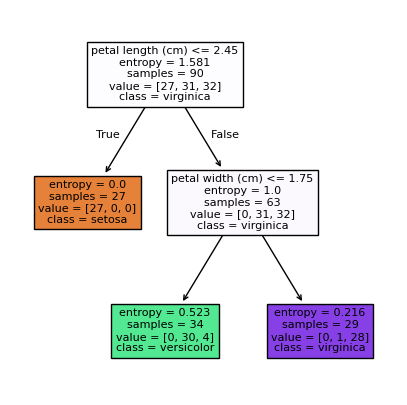

In [10]:

plt.figure(figsize=(5,5))
plot_tree(dt, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


In [11]:

# cm = confusion_matrix(y_test, y_pred)
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
# plt.xlabel("Predicted")
# plt.ylabel("True")
# plt.title("Confusion Matrix")
# plt.show()



## 4️⃣ Controlling Overfitting with Hyperparameters
Decision Trees can overfit! We can control complexity using:
- **max_depth**: Maximum depth of the tree.
- **min_samples_split**: Minimum samples needed to split.
- **criterion**: 'gini' or 'entropy' for measuring impurity.


In [12]:

dt_depth = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_depth.fit(X_train, y_train)
print("Accuracy (max_depth=3):", accuracy_score(y_test, dt_depth.predict(X_test)))


Accuracy (max_depth=3): 0.9833333333333333


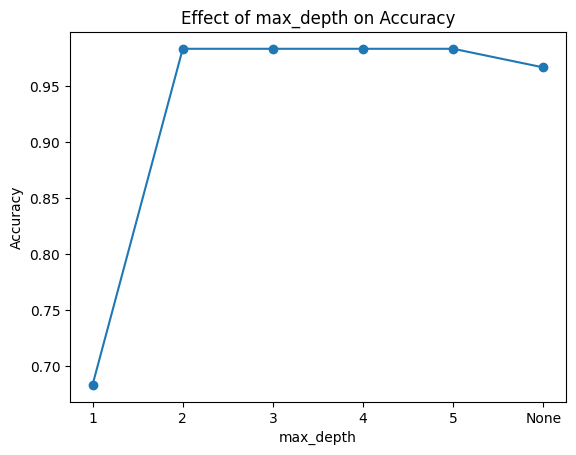

In [13]:

depths = [1, 2, 3, 4, 5, None]
acc_scores = []

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    acc_scores.append(accuracy_score(y_test, model.predict(X_test)))

plt.plot([str(d) for d in depths], acc_scores, marker='o')
plt.title("Effect of max_depth on Accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.show()



## 5️⃣ Introduction to Random Forest
A **Random Forest** is an **ensemble** of multiple Decision Trees.
- Uses **Bagging** (Bootstrap Aggregation).
- Reduces overfitting.
- Improves accuracy and generalization.


In [14]:

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_rf_pred = rf.predict(X_test)
print("🌲 Random Forest Accuracy:", accuracy_score(y_test, y_rf_pred))


🌲 Random Forest Accuracy: 0.9833333333333333


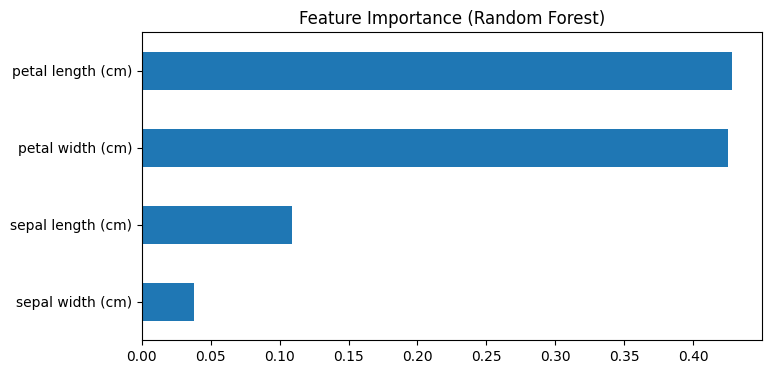

In [15]:

importances = pd.Series(rf.feature_importances_, index=iris.feature_names)
importances.sort_values().plot(kind='barh', figsize=(8,4))
plt.title("Feature Importance (Random Forest)")
plt.show()



## 🏋️ Hands-on Exercises:
1. Change `max_depth` and observe the tree's complexity.
2. Compare `criterion='gini'` vs. `criterion='entropy'`.
3. Train a Random Forest with `n_estimators` = 10, 50, 200. Observe accuracy.
4. Use the **Wine Dataset** (`load_wine()`) and repeat steps.
5. Plot feature importance for the Wine dataset.

---



## ✅ Wrap-up & Key Points:
- Decision Trees are interpretable but can overfit.
- Hyperparameters help control complexity.
- Random Forests aggregate multiple trees to reduce variance.
- Feature importance helps explain model decisions.

🎯 **Next Steps:** Explore Gradient Boosting & XGBoost!
